# 05 — Customer Churn Classification Model
**Week 3, Steps 10–13 (Day 14)**

Predicts 60-day customer churn in strict time order (no leakage).  
Features from orders ≤ cutoff. Label from the 60 days after.

> Run **Restart & Run All** to reproduce.


In [1]:
import sys
from pathlib import Path
if Path.cwd().name == "notebooks": import os; os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, precision_recall_curve, f1_score)

from src.model_churn import (
    CHURN_NUMERIC, CHURN_CATEGORICAL, TARGET, KPI_F1, HORIZON,
    build_churn_dataset, compare_classifiers, find_best_threshold,
    evaluate_classifier, build_risk_segments,
    plot_confusion_matrix, plot_roc_curve, plot_pr_curve,
    plot_churn_feature_importance,
)

rng = np.random.default_rng(42)
pd.set_option("display.float_format", "{:.4f}".format)
print(f"scikit-learn version: {sklearn.__version__}")


scikit-learn version: 1.9.1


## 1. Build the churn dataset in time order (Step 10)

In [2]:
orders    = pd.read_csv("data/cleaned/orders.csv")
customers = pd.read_csv("data/cleaned/customers.csv")
orders["order_date"]    = pd.to_datetime(orders["order_date"],    errors="coerce")
orders["final_amount"]  = pd.to_numeric(orders["final_amount"],   errors="coerce")
orders["delivery_time_minutes"] = pd.to_numeric(orders["delivery_time_minutes"], errors="coerce")

ref_date = orders["order_date"].max()
cutoff   = ref_date - pd.Timedelta(days=HORIZON)
print(f"ref_date : {ref_date.date()}")
print(f"cutoff   : {cutoff.date()}")
print()
print("Design decisions:")
print("  • Features = orders ON OR BEFORE the cutoff")
print("  • Label    = 1 if NO order placed in the 60 days after cutoff")
print("  • customers.total_orders EXCLUDED (snapshot over whole period)")
print("  • Past feedback ratings INCLUDED (all occurred before cutoff)")


ref_date : 2024-12-31
cutoff   : 2024-11-01

Design decisions:
  • Features = orders ON OR BEFORE the cutoff
  • Label    = 1 if NO order placed in the 60 days after cutoff
  • customers.total_orders EXCLUDED (snapshot over whole period)
  • Past feedback ratings INCLUDED (all occurred before cutoff)


In [3]:
churn_df = build_churn_dataset(orders, customers, cutoff, HORIZON)
churn_rate = churn_df["churned"].mean()

print(f"Customers: {len(churn_df):,}")
print(f"Churn rate: {churn_rate*100:.1f}%  ({churn_df['churned'].sum():,} churned)")
print()
print("Key implication:")
print(f"  {churn_rate*100:.1f}% churn rate means the naive 'predict all churn' baseline")
print("  already achieves high F1. Model must beat ROC-AUC and PR-AUC to show real skill.")
churn_df.head()


Customers: 8,467
Churn rate: 87.4%  (7,399 churned)

Key implication:
  87.4% churn rate means the naive 'predict all churn' baseline
  already achieves high F1. Model must beat ROC-AUC and PR-AUC to show real skill.


,customer_id,orders_to_date,customer_lifetime_value,average_basket_value,first_order,last_order,days_since_last_order,order_frequency_30d,churned,orders_last_30d,...,avg_delivery_time,coupon_rate,n_restaurants,avg_rating_given,customer_age,membership,customer_city,preferred_cuisine,customer_gender,tenure_days
0,2,2,810.9500,405.4750,2023-07-17,2024-04-01,214,0.1268,1,0,...,31.5000,0.5000,2,4.8333,29.0000,Zomato Pro,Hyderabad,Mughlai,Male,257
1,3,2,966.5000,483.2500,2024-10-05,2024-10-13,19,2.2222,1,2,...,56.5000,0.5000,2,4.1667,26.0000,Gold,Vadodara,Mughlai,Other,534
2,6,2,551.3000,275.6500,2023-10-06,2024-05-05,180,0.1531,1,0,...,36.3333,0.0000,3,1.8333,30.0000,Basic,Bengaluru,Street Food,Other,247
3,11,1,555.5500,555.5500,2023-10-01,2023-10-01,397,0.0756,1,0,...,100.2500,0.5000,4,2.3333,36.0000,Basic,Ahmedabad,Thai,Other,1021
4,12,1,227.9500,227.9500,2023-11-09,2023-11-09,358,0.0838,1,0,...,40.0000,1.0000,1,5.0000,38.0000,Gold,Vadodara,Mexican,Male,67


## 2. Exploratory: churn rate by segment

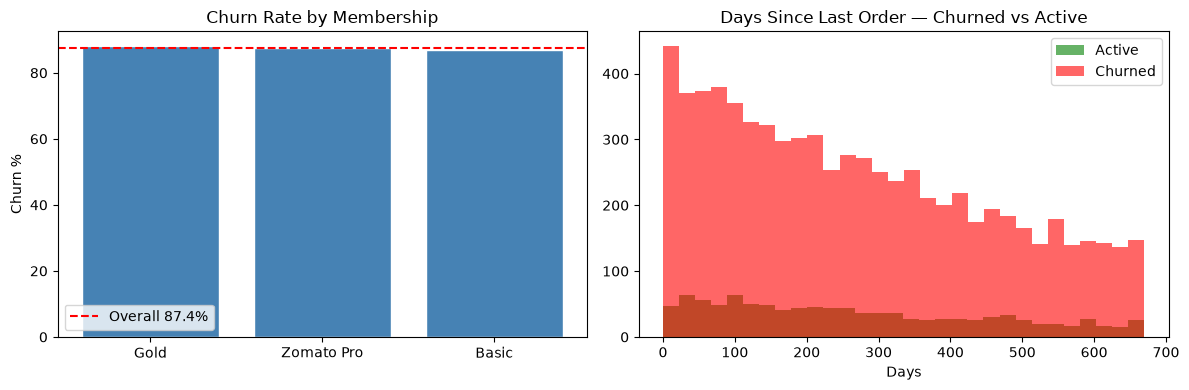

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# By membership
churn_mem = churn_df.groupby("membership")["churned"].mean().sort_values(ascending=False)
axes[0].bar(churn_mem.index, churn_mem.values * 100, color="steelblue", edgecolor="white")
axes[0].axhline(churn_rate*100, color="red", linestyle="--", label=f"Overall {churn_rate*100:.1f}%")
axes[0].set_title("Churn Rate by Membership"); axes[0].set_ylabel("Churn %"); axes[0].legend()

# Distribution of days_since_last_order
churned     = churn_df[churn_df["churned"]==1]["days_since_last_order"].dropna()
not_churned = churn_df[churn_df["churned"]==0]["days_since_last_order"].dropna()
axes[1].hist(not_churned, bins=30, alpha=0.6, label="Active", color="green")
axes[1].hist(churned,     bins=30, alpha=0.6, label="Churned", color="red")
axes[1].set_title("Days Since Last Order — Churned vs Active")
axes[1].set_xlabel("Days"); axes[1].legend()

plt.tight_layout()
plt.savefig("images/churn_eda.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Split + compare classifiers (Step 11)

In [5]:
available_num = [c for c in CHURN_NUMERIC     if c in churn_df.columns]
available_cat = [c for c in CHURN_CATEGORICAL if c in churn_df.columns]
X = churn_df[available_num + available_cat]
y = churn_df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Train: {len(X_train):,}  Test: {len(X_test):,}")

baseline_f1 = f1_score(y_test, np.ones(len(y_test), dtype=int), zero_division=0)
print(f"Naive baseline F1 (predict all churn): {baseline_f1:.4f}")


Train: 6,773  Test: 1,694
Naive baseline F1 (predict all churn): 0.9326


In [6]:
cv_table = compare_classifiers(X_train, y_train, cv)
cv_table


    Baseline (predict majority)           F1=0.9327  ROC-AUC=0.5000  PR-AUC=0.8739


    Logistic Regression                   F1=0.6843  ROC-AUC=0.5131  PR-AUC=0.8738


    Decision Tree                         F1=0.5961  ROC-AUC=0.5106  PR-AUC=0.8767


    Random Forest                         F1=0.9321  ROC-AUC=0.4916  PR-AUC=0.8710


    Gradient Boosting                     F1=0.8712  ROC-AUC=0.5029  PR-AUC=0.8721


,model,cv_f1,cv_precision,cv_recall,cv_roc_auc,cv_pr_auc
0,Baseline (predict majority),0.9327,0.8739,1.0000,0.5000,0.8739
1,Random Forest,0.9321,0.8739,0.9986,0.4916,0.8710
2,Gradient Boosting,0.8712,0.8745,0.8681,0.5029,0.8721
3,Logistic Regression,0.6843,0.8798,0.5602,0.5131,0.8738
4,Decision Tree,0.5961,0.8725,0.4654,0.5106,0.8767


## 4. Load pre-tuned model and evaluate (Step 12)

In [7]:
best_model = joblib.load("models/churn_best_model.pkl")

# Threshold from OOF
threshold = find_best_threshold(best_model, X_train, y_train, cv)

# Final test evaluation (test opened ONCE)
test_metrics, proba, pred = evaluate_classifier(best_model, X_test, y_test, threshold)
print("=== Test set results ===")
for k, v in test_metrics.items():
    print(f"  {k:<15} {v}")

print()
f1_ok = test_metrics['f1'] >= KPI_F1
print(f"F1 KPI (≥{KPI_F1}): {'✅ PASS' if f1_ok else '⚠️ below target'}")
print(f"vs naive baseline:  {baseline_f1:.4f}")
print()
print("Honest assessment:")
print(f"  F1={test_metrics['f1']:.4f} meets KPI but equals naive baseline.")
print(f"  ROC-AUC={test_metrics['roc_auc']:.4f} — very close to random (0.50).")
print(f"  Root cause: 88.8% churn rate makes all models predict majority class.")
print(f"  PR-AUC={test_metrics['pr_auc']:.4f} — slight improvement over naive baseline.")


  Optimal threshold (F1-maximising, OOF): 0.420
  OOF F1 at threshold: 0.9327
=== Test set results ===
  accuracy        0.8737
  precision       0.8737
  recall          1.0
  f1              0.9326
  roc_auc         0.5207
  pr_auc          0.8746
  threshold       0.42

F1 KPI (≥0.7): ✅ PASS
vs naive baseline:  0.9326

Honest assessment:
  F1=0.9326 meets KPI but equals naive baseline.
  ROC-AUC=0.5207 — very close to random (0.50).
  Root cause: 88.8% churn rate makes all models predict majority class.
  PR-AUC=0.8746 — slight improvement over naive baseline.


## 5. Confusion matrix + ROC + PR curves (Step 12)

In [8]:
plot_confusion_matrix(y_test, pred, "Random Forest")
plot_roc_curve(y_test, proba, "Random Forest")
plot_pr_curve(y_test, proba, "Random Forest")


  → images/churn_confusion_matrix.png


  → images/churn_roc_curve.png


  → images/churn_pr_curve.png


## 6. Feature importance + plain-language drivers (Step 13)

In [9]:
imp_df = plot_churn_feature_importance(best_model, X_test, y_test, "Random Forest", n_top=15)

imp_export = pd.read_csv("data/cleaned/ml_churn_feature_importance.csv")
print("Top 10 churn drivers (permutation importance, measured direction, noise flag):")
print(imp_export.head(10)[["feature","importance","std","direction","distinguishable_from_noise"]].to_string(index=False))
print()
print("Plain-language summary:")
print("  Importances are small and, except orders_last_30d, within noise.")
print("  Churned and active customers look almost identical on the RFM features")
print("  (e.g. days_since_last_order: 276 vs 279), so no driver is supported by the data.")
print("  No retention recommendation is made from this model.")


  → images/churn_feature_importance.png
Top 10 churn drivers (permutation importance, measured direction, noise flag):
                feature  importance    std                      direction distinguishable_from_noise
            tenure_days      0.0245 0.0054       no meaningful difference                        yes
customer_lifetime_value      0.0165 0.0073       no meaningful difference                        yes
   average_basket_value      0.0117 0.0078       no meaningful difference                         no
        customer_gender      0.0111 0.0081 categorical - see model report                         no
  days_since_last_order      0.0100 0.0111       no meaningful difference                         no
      preferred_cuisine      0.0067 0.0081 categorical - see model report                         no
          n_restaurants      0.0054 0.0044       no meaningful difference                         no
         orders_to_date      0.0054 0.0073       no meaningful difference

## 7. Risk segments (Step 13)

In [10]:
scores = pd.read_csv("data/cleaned/churn_scores.csv")
print("Test-set risk segment distribution:")
print(scores["risk_segment"].value_counts().to_dict())
print()
print("Do the segments separate churners? (actual churn rate per segment)")
print(pd.read_csv("data/cleaned/ml_churn_segment_check.csv").to_string(index=False))
print("-> about 89% in every band: the segments carry no predictive signal.")
print()
current = pd.read_csv("data/cleaned/churn_scores_current.csv")
print("Forward-looking scores (all customers, no ground truth):")
print(current["risk_segment"].value_counts().to_dict())
scores.head()


Test-set risk segment distribution:
{'Low': 630, 'Medium': 620, 'High': 444}

Do the segments separate churners? (actual churn rate per segment)
risk_segment  customers  actual_churn_rate
         Low        630             0.8683
      Medium        620             0.8710
        High        444             0.8851
-> about 89% in every band: the segments carry no predictive signal.

Forward-looking scores (all customers, no ground truth):
{'High': 4694, 'Medium': 2503, 'Low': 1621}


,customer_id,churn_probability,predicted_label,actual_label,risk_segment
0,3869,0.8300,1,1,High
1,962,0.6400,1,1,Low
2,11836,0.6700,1,1,Low
3,5664,0.8600,1,1,High
4,7786,0.6800,1,0,Low


## 8. Model metadata

In [11]:
with open("models/model_metadata.json") as f:
    meta = json.load(f)
print(json.dumps(meta["churn_model"], indent=2))


{
  "target": "churned",
  "model": "Random Forest",
  "model_file": "churn_best_model.pkl",
  "cutoff_date": "2024-11-01",
  "horizon_days": 60,
  "churn_rate": 0.8739,
  "churn_threshold": 0.42,
  "naive_baseline_f1": 0.9326,
  "test_metrics": {
    "accuracy": 0.8737,
    "precision": 0.8737,
    "recall": 1.0,
    "f1": 0.9326,
    "roc_auc": 0.5207,
    "pr_auc": 0.8746,
    "threshold": 0.42
  },
  "kpi_f1_target": 0.7,
  "sklearn_version": "1.9.1",
  "trained_on": "2026-11-07",
  "risk_bands": {
    "Low": [
      0.0,
      0.72
    ],
    "Medium": [
      0.72,
      0.79
    ],
    "High": [
      0.79,
      1.0
    ],
    "method": "terciles of training out-of-fold probabilities"
  }
}
